# Aula 06 - CNN (Qua, 09.09.2026)

# Setup

In [1]:
# Importar bibliotecas utilizadas no notebook

import os
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Definir sementes para tornar os experimentos mais reproduzíveis

np.random.seed(42)
tf.random.set_seed(42)


# Carregamento dos Dados

In [2]:
# Carregar o Fashion-MNIST
#
# Se o arquivo utilizado nos laboratórios anteriores estiver disponível,
# ele será utilizado. Caso contrário, o próprio Keras fará o download do dataset.

if os.path.exists("fashion_mnist.npz"):
    dados = np.load("fashion_mnist.npz")

    X_train = dados["X_train"]
    y_train = dados["y_train"]
    X_test = dados["X_test"]
    y_test = dados["y_test"]

    origem = "arquivo local fashion_mnist.npz"
else:
    (X_train, y_train), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()
    origem = "keras.datasets.fashion_mnist"

nomes_classes = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print(f"Origem dos dados: {origem}")
print(f"Treinamento: {X_train.shape}")
print(f"Teste: {X_test.shape}")
print(f"Quantidade de classes: {len(np.unique(y_train))}")
print(f"Tipo dos pixels: {X_train.dtype}")
print(f"Intervalo original dos pixels: {X_train.min()} a {X_train.max()}")


Origem dos dados: arquivo local fashion_mnist.npz
Treinamento: (60000, 28, 28)
Teste: (10000, 28, 28)
Quantidade de classes: 10
Tipo dos pixels: uint8
Intervalo original dos pixels: 0 a 255


## Perguntas

1. Qual é a dimensão de cada imagem e quantas classes existem no Fashion-MNIST?  
2. No laboratório anterior com MLP, uma imagem 28 × 28 era transformada em 784 valores. Por que, em uma CNN, é interessante preservar a estrutura 28 × 28 da imagem?  
3. As imagens do Fashion-MNIST estão em escala de cinza. Quantos canais possui cada imagem? Se fossem imagens RGB, qual seria a profundidade da entrada?

# Preparação da Entrada para a CNN

In [3]:
# Normalizar os pixels para o intervalo entre 0 e 1

X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Adicionar explicitamente a dimensão correspondente ao canal
#
# Antes:  (quantidade, altura, largura)
# Depois: (quantidade, altura, largura, canais)

X_train = np.expand_dims(X_train, axis=-1)
X_test = np.expand_dims(X_test, axis=-1)

print(f"Shape de X_train: {X_train.shape}")
print(f"Shape de X_test:  {X_test.shape}")
print(f"Shape de uma imagem: {X_train[0].shape}")
print(f"Intervalo após normalização: {X_train.min():.1f} a {X_train.max():.1f}")


Shape de X_train: (60000, 28, 28, 1)
Shape de X_test:  (10000, 28, 28, 1)
Shape de uma imagem: (28, 28, 1)
Intervalo após normalização: 0.0 a 1.0


## Perguntas

4. Por que foi necessário adicionar uma nova dimensão ao final das imagens com `np.expand_dims(..., axis=-1)`?  
5. Qual é o formato que a CNN recebe para **uma única imagem** deste dataset? O que representa cada uma dessas dimensões?  
6. Por que os valores dos pixels foram divididos por 255?

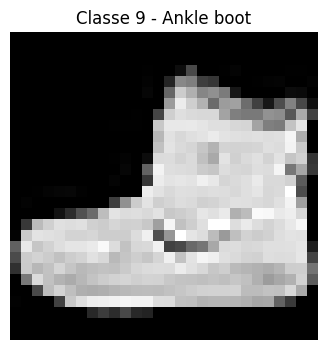

Shape da imagem exibida: (28, 28, 1)


In [4]:
# Visualizar uma imagem utilizada como entrada da CNN

indice = 0

plt.figure(figsize=(4, 4))
plt.imshow(X_train[indice, :, :, 0], cmap="gray")
plt.title(f"Classe {y_train[indice]} - {nomes_classes[y_train[indice]]}")
plt.axis("off")
plt.show()

print(f"Shape da imagem exibida: {X_train[indice].shape}")


# Construção da CNN

In [5]:
# Construir uma CNN utilizando os hiperparâmetros estudados em aula

model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # 1ª camada convolucional
    layers.Conv2D(
        filters=8,
        kernel_size=(3, 3),
        strides=(1, 1),
        padding="valid",
        activation="relu",
        name="conv1"
    ),

    # 2ª camada convolucional
    layers.Conv2D(
        filters=16,
        kernel_size=(5, 5),
        strides=(2, 2),
        padding="same",
        activation="relu",
        name="conv2"
    ),

    # 3ª camada convolucional
    layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        strides=(1, 1),
        padding="valid",
        activation="relu",
        name="conv3"
    ),

    # Converter os mapas de características em um vetor
    # para conectar a CNN à camada Dense de classificação
    layers.Flatten(),

    # Camada de saída: 10 classes do Fashion-MNIST
    layers.Dense(10, activation="softmax")
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 26, 26, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 13, 13, 16)     │         3,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3872)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        38,730 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,666 (182.29 KB)

 Trainable params: 46,666 (182.29 KB)

 Non-trainable params: 0 (0.00 B)

## Perguntas

7. Na primeira camada, o que significa `filters=8`?  
8. Considerando que a entrada possui 1 canal, qual é a dimensão completa de **cada filtro** da primeira camada?  
9. Por que a saída da primeira camada possui profundidade 8?  
10. A segunda camada recebe 8 mapas de características. Qual é, portanto, a profundidade de cada filtro dessa camada? Qual é a dimensão completa de um filtro `5 × 5` nessa camada?  
11. A terceira camada recebe 16 mapas da camada anterior e possui 32 filtros. Qual é a dimensão completa de cada filtro e quantos mapas de características serão produzidos?  
12. Qual é o papel da função ReLU depois da convolução? Relacione sua resposta com as matrizes $Z$ e $A$.

# Profundidade dos Filtros e Parâmetros Treináveis

In [6]:
# Inspecionar a forma real dos kernels aprendidos por cada camada Conv2D
#
# O TensorFlow armazena o kernel de uma Conv2D no formato:
# (altura_kernel, largura_kernel, canais_entrada, quantidade_filtros)

for nome_camada in ["conv1", "conv2", "conv3"]:
    camada = model.get_layer(nome_camada)
    kernel, bias = camada.get_weights()

    print(f"{nome_camada}")
    print(f"  Shape do kernel completo: {kernel.shape}")
    print(f"  Shape dos biases:         {bias.shape}")
    print(f"  Parâmetros treináveis:    {camada.count_params()}")
    print()


conv1
  Shape do kernel completo: (3, 3, 1, 8)
  Shape dos biases:         (8,)
  Parâmetros treináveis:    80

conv2
  Shape do kernel completo: (5, 5, 8, 16)
  Shape dos biases:         (16,)
  Parâmetros treináveis:    3216

conv3
  Shape do kernel completo: (3, 3, 16, 32)
  Shape dos biases:         (32,)
  Parâmetros treináveis:    4640



## Perguntas

13. Observe os shapes exibidos. Quantas matrizes de pesos existem **dentro de um único filtro** da `conv1`, da `conv2` e da `conv3`? Por quê?  
14. Calcule manualmente a quantidade de parâmetros treináveis da `conv1`. Considere os pesos dos kernels e um bias para cada filtro.  
15. Calcule manualmente a quantidade de parâmetros treináveis da `conv2`.  
16. Por que o número de parâmetros de uma camada convolucional depende do tamanho do kernel, da profundidade da entrada e da quantidade de filtros, mas não diretamente da altura e largura completas da imagem? Relacione com o compartilhamento dos pesos do filtro durante o deslocamento.

# Efeito de Stride e Padding

In [7]:
# Comparar o formato da saída para diferentes configurações de stride e padding
# usando sempre uma entrada 28 × 28 × 1 e 8 filtros.

entrada_exemplo = tf.zeros((1, 28, 28, 1))

configuracoes = [
    ("3x3 | stride 1 | valid", (3, 3), (1, 1), "valid"),
    ("3x3 | stride 1 | same",  (3, 3), (1, 1), "same"),
    ("3x3 | stride 2 | same",  (3, 3), (2, 2), "same")
]

for descricao, kernel_size, strides, padding in configuracoes:
    camada = layers.Conv2D(
        filters=8,
        kernel_size=kernel_size,
        strides=strides,
        padding=padding
    )

    saida = camada(entrada_exemplo)

    print(f"{descricao:27s} -> saída: {tuple(saida.shape)}")


3x3 | stride 1 | valid      -> saída: (1, 26, 26, 8)
3x3 | stride 1 | same       -> saída: (1, 28, 28, 8)
3x3 | stride 2 | same       -> saída: (1, 14, 14, 8)


## Perguntas

17. Compare `padding="valid"` e `padding="same"` com `stride=(1,1)`. O que aconteceu com a altura e a largura da saída?  
18. Mantendo `padding="same"`, o que aconteceu quando o stride passou de 1 para 2?  
19. Em todos os testes foram utilizados 8 filtros. Por que a última dimensão da saída continuou sendo 8, independentemente do stride e do padding?

# Treinamento da CNN

In [8]:
# Configurar o processo de treinamento
#
# Os mesmos conceitos estudados nas MLPs continuam presentes:
# função de perda, otimizador, taxa de aprendizado e métrica.

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Treinar a CNN

historico = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.20,
    verbose=1
)


Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 30s 76ms/step - accuracy: 0.7975 - loss: 0.5868 - val_accuracy: 0.8497 - val_loss: 0.4358
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 32s 86ms/step - accuracy: 0.8658 - loss: 0.3816 - val_accuracy: 0.8709 - val_loss: 0.3740
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 28s 75ms/step - accuracy: 0.8818 - loss: 0.3321 - val_accuracy: 0.8823 - val_loss: 0.3388
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 40s 73ms/step - accuracy: 0.8925 - loss: 0.3008 - val_accuracy: 0.8873 - val_loss: 0.3247
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 74ms/step - accuracy: 0.9009 - loss: 0.2764 - val_accuracy: 0.8917 - val_loss: 0.3101


## Perguntas

20. Quais hiperparâmetros de treinamento presentes nas MLPs continuam sendo utilizados normalmente nesta CNN? Cite pelo menos quatro.  
21. Quais parâmetros são aprendidos nas camadas `Conv2D` durante o treinamento? Como a backpropagation participa desse processo?  
22. Apesar de a CNN calcular suas camadas de forma diferente de uma MLP, por que continuamos utilizando função de perda e otimizador?

# Avaliação

Loss no teste:     0.3211
Acurácia no teste: 0.8826


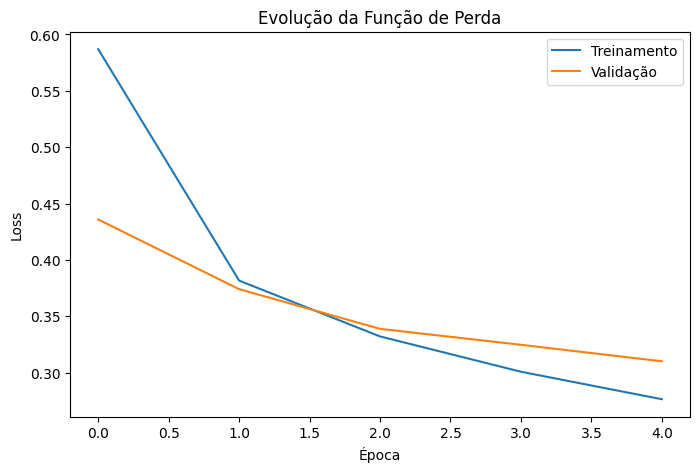

In [9]:
# Avaliar o modelo no conjunto de teste

loss_teste, acuracia_teste = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"Loss no teste:     {loss_teste:.4f}")
print(f"Acurácia no teste: {acuracia_teste:.4f}")

# Visualizar a evolução da loss de treinamento e validação

plt.figure(figsize=(8, 5))
plt.plot(historico.history["loss"], label="Treinamento")
plt.plot(historico.history["val_loss"], label="Validação")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("Evolução da Função de Perda")
plt.legend()
plt.show()


# Visualização dos Mapas de Características

Shape da entrada: (1, 28, 28, 1)
Shape da saída da conv1: (26, 26, 8)


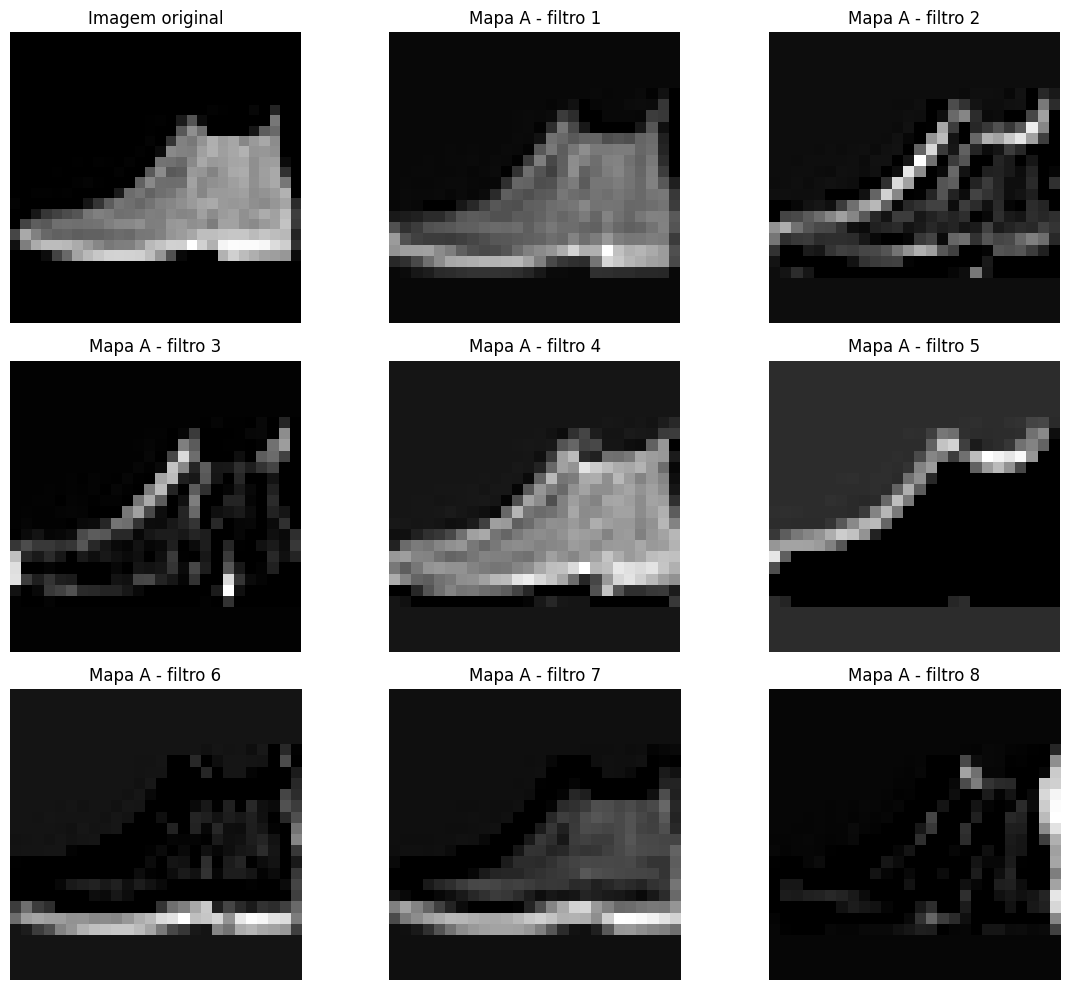

In [10]:
# Criar um modelo auxiliar que retorna a saída da primeira camada convolucional

extrator_conv1 = keras.Model(
    inputs=model.inputs,
    outputs=model.get_layer("conv1").output
)

# Selecionar uma única imagem de teste

indice = 0
imagem = X_test[indice:indice + 1]

# Obter os 8 mapas de características gerados pelos 8 filtros da primeira camada

mapas_conv1 = extrator_conv1.predict(imagem, verbose=0)[0]

print(f"Shape da entrada: {imagem.shape}")
print(f"Shape da saída da conv1: {mapas_conv1.shape}")

# Exibir a imagem original e os 8 mapas de características

plt.figure(figsize=(12, 10))

plt.subplot(3, 3, 1)
plt.imshow(imagem[0, :, :, 0], cmap="gray")
plt.title("Imagem original")
plt.axis("off")

for i in range(8):
    plt.subplot(3, 3, i + 2)
    plt.imshow(mapas_conv1[:, :, i], cmap="gray")
    plt.title(f"Mapa A - filtro {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


## Perguntas

23. Todos os 8 filtros receberam exatamente a mesma imagem. Por que os 8 mapas de características produzidos são diferentes?  
24. Explique, com suas palavras, a afirmação: **“cada filtro atua sobre todos os canais da entrada, combina os resultados e produz um único mapa de características”**.